In [1]:

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tqdm import tqdm
from pathlib import Path
import urllib.request
import zipfile
import copy
import sys

torch.manual_seed(42)




In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

project_dir = Path.cwd()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
results_dir = project_dir / "results"
data_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
zip_path = data_dir / "hymenoptera_data.zip"
dataset_path = data_dir / "hymenoptera_data"

if not dataset_path.exists():
    if not zip_path.exists():
        urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(data_dir)

print("Dataset ready!")

Device: cpu
Dataset ready!


In [3]:

data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),
    "eval": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

trainset = datasets.ImageFolder(
    str(dataset_path / "train"),
    transform=data_transforms["train"]
)

heldoutset = datasets.ImageFolder(
    str(dataset_path / "val"),
    transform=data_transforms["eval"]
)

# Split the original validation folder into
# separate validation and test subsets
indices = list(range(len(heldoutset)))

val_indices, test_indices = train_test_split(
    indices,
    test_size=0.5,
    random_state=42,
    stratify=heldoutset.targets
)

valset = Subset(heldoutset, val_indices)
testset = Subset(heldoutset, test_indices)

batch_size = 4

trainloader = DataLoader(
    trainset, batch_size=batch_size,
    shuffle=True, num_workers=0
)

valloader = DataLoader(
    valset, batch_size=batch_size,
    shuffle=False, num_workers=0
)

testloader = DataLoader(
    testset, batch_size=batch_size,
    shuffle=False, num_workers=0
)

class_names = trainset.classes

print("Classes:", class_names)
print("Training:", len(trainset))
print("Validation:", len(valset))
print("Testing:", len(testset))


Classes: ['ants', 'bees']
Training: 244
Validation: 76
Testing: 77


In [4]:

def evaluate(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    running_corrects = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            running_corrects += (outputs.argmax(dim=1) == labels).sum().item()
            total += inputs.size(0)

    return running_loss / total, 100 * running_corrects / total


In [5]:

def train_model(model, criterion, optimizer, scheduler,
                num_epochs=10, feature_extraction=False):

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(num_epochs):

        if feature_extraction:
            model.eval()
            model.fc.train()
        else:
            model.train()

        running_loss = 0.0
        running_corrects = 0
        total = 0

        progress = tqdm(
            trainloader,
            desc=f"Epoch {epoch+1:2d}/{num_epochs}",
            ascii="─━",
            bar_format="{desc} {percentage:3.0f}% |{bar}| {n_fmt}/{total_fmt}",
            leave=True,
            file=sys.stdout
        )

        for inputs, labels in progress:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += (outputs.argmax(dim=1) == labels).sum().item()
            total += inputs.size(0)

        scheduler.step()

        train_loss = running_loss / total
        train_acc = 100 * running_corrects / total

        # Validation after epoch
        val_loss, val_acc = evaluate(
            model, valloader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%"
        )

        if val_acc > best_acc:
            best_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_model_wts)

    print(f"Best Validation Accuracy: {best_acc:.2f}%")

    return model, history, best_acc


Part (a): Fine-tune ResNet18

In [6]:

# Load ImageNet1K pretrained ResNet18
model_ft = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Replace final layer
num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, 2)

model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()

# Train all network parameters
optimizer_ft = optim.SGD(
    model_ft.parameters(),
    lr=0.001,
    momentum=0.9
)

scheduler_ft = lr_scheduler.StepLR(
    optimizer_ft,
    step_size=7,
    gamma=0.1
)

print("Training ResNet18 - Fine-tuning")

model_ft, history_ft, best_acc_ft = train_model(
    model_ft,
    criterion,
    optimizer_ft,
    scheduler_ft,
    num_epochs=10
)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\dmcol/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:09<00:00, 4.97MB/s]


Training ResNet18 - Fine-tuning
Epoch  1/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.6497 | Train Acc: 65.16% | Val Loss: 0.2565 | Val Acc: 89.47%
Epoch  2/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.4795 | Train Acc: 81.15% | Val Loss: 0.2108 | Val Acc: 92.11%
Epoch  3/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.7866 | Train Acc: 75.82% | Val Loss: 0.2063 | Val Acc: 90.79%
Epoch  4/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.4750 | Train Acc: 80.33% | Val Loss: 0.2404 | Val Acc: 93.42%
Epoch  5/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.5728 | Train Acc: 79.10% | Val Loss: 0.3172 | Val Acc: 81.58%
Epoch  6/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.7014 | Train Acc: 75.00% | Val Loss: 0.2624 | Val Acc: 89.47%
Epoch  7/10 100% |━━━━━━━━━━| 61/61
Train Loss: 1.0272 | Train Acc: 67.21% | Val Loss: 0.2575 | Val Acc: 90.79%
Epoch  8/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.3279 | Train Acc: 88.93% | Val Loss: 0.2108 | Val Acc: 90.79%
Epoch  9/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.4746 | Train Acc: 80.3

Part (b): Feature extraction

In [7]:

# Load ImageNet1K pretrained ResNet18
model_conv = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Freeze pretrained parameters
for param in model_conv.parameters():
    param.requires_grad = False

# Replace final layer
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Train only final classification layer
optimizer_conv = optim.SGD(
    model_conv.fc.parameters(),
    lr=0.001,
    momentum=0.9
)

scheduler_conv = lr_scheduler.StepLR(
    optimizer_conv,
    step_size=7,
    gamma=0.1
)

print("Training ResNet18 - Feature Extraction")

model_conv, history_conv, best_acc_conv = train_model(
    model_conv,
    criterion,
    optimizer_conv,
    scheduler_conv,
    num_epochs=10,
    feature_extraction=True
)


Training ResNet18 - Feature Extraction
Epoch  1/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.3197 | Train Acc: 84.02% | Val Loss: 0.1265 | Val Acc: 93.42%
Epoch  2/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.2216 | Train Acc: 90.98% | Val Loss: 0.1192 | Val Acc: 97.37%
Epoch  3/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.1301 | Train Acc: 94.67% | Val Loss: 0.1196 | Val Acc: 97.37%
Epoch  4/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.1088 | Train Acc: 95.08% | Val Loss: 0.1217 | Val Acc: 97.37%
Epoch  5/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.1011 | Train Acc: 96.31% | Val Loss: 0.1733 | Val Acc: 96.05%
Epoch  6/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.1180 | Train Acc: 95.08% | Val Loss: 0.1503 | Val Acc: 96.05%
Epoch  7/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.0821 | Train Acc: 96.31% | Val Loss: 0.1315 | Val Acc: 97.37%
Epoch  8/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.0783 | Train Acc: 97.54% | Val Loss: 0.1218 | Val Acc: 97.37%
Epoch  9/10 100% |━━━━━━━━━━| 61/61
Train Loss: 0.0828 | Train Ac

In [8]:
#final Testing

criterion = nn.CrossEntropyLoss()

ft_test_loss, ft_test_acc = evaluate(
    model_ft, testloader, criterion
)

conv_test_loss, conv_test_acc = evaluate(
    model_conv, testloader, criterion
)

print("\nFINAL TEST RESULTS")
print("-" * 50)

print(
    f"Fine-tuning       | Test Accuracy: {ft_test_acc:.2f}%"
)

print(
    f"Feature Extraction | Test Accuracy: {conv_test_acc:.2f}%"
)



FINAL TEST RESULTS
--------------------------------------------------
Fine-tuning       | Test Accuracy: 89.61%
Feature Extraction | Test Accuracy: 94.81%


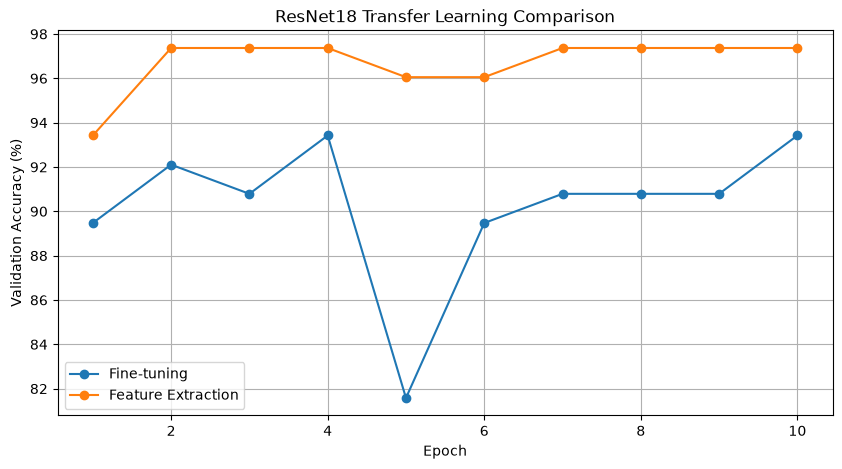

In [9]:

epochs = range(1, 11)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs, history_ft["val_acc"],
    marker="o", label="Fine-tuning"
)

plt.plot(
    epochs, history_conv["val_acc"],
    marker="o", label="Feature Extraction"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("ResNet18 Transfer Learning Comparison")
plt.legend()
plt.grid(True)

plt.savefig(
    results_dir / "Q3_ResNet18_Comparison.png",
    dpi=300
)

plt.show()
